<center>
    <b>
        <font size=5> Decoding Behavioral Choice from Neural Data 

<center> 
    <font size=4><b><u>Introduction</u></b>
        <br>As people move through the world, the brain processes the intention before an action happens. For example, if there are two cookies are in front of you, you choose in your mind which cookie you will take before reaching for it. As such, this choice (or 'intent') is represented in neural signals before any observable movement happens.<br><br>
        Many brain computer interfaces (BCIs) rely on these intent signals to create seamless transitions between human thoughts and computer/robot actions. Such technology would help the millions who suffer from limb loss, paralysis, and other movement disorders to live their lives fully and unobstructed. <br><br>
        As such, much of neuroscience research is dedicated to understanding (or 'decoding') the chatter of neural signals in the brain. Here, I built a simple decoding algorithm to predict the intent of neural signals measured in people. I show that this decoding algorithm can predict the future choice a person makes with a 90% accuracy. 
        

<cite paper, neural data source, etc> 
    

In [1]:
import pandas as pd
import numpy as np
from pynwb import NWBHDF5IO
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
from scipy.ndimage import gaussian_filter
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier()

In [2]:
#%config InlineBackend.figure_format = 'svg' #for super high rez
%config InlineBackend.figure_format = 'png' #for regular rez

In [3]:
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.left'] = True
plt.rcParams['figure.dpi'] = 300

In [4]:
io = NWBHDF5IO('/Users/ac/Ephys Projects/000469/sub-2/sub-2_ses-2_ecephys+image.nwb', 'r')
nwbfile = io.read()

In [5]:
spike_times_all = nwbfile.units.columns[0] #extract out only spike times
spike_ms = [x * 1000 for x in spike_times_all] # convert to ms scale

<center>
    <font size=4><b><u>Big Picture</u></b><br>Neural signal data (single unit electrophysiology) is collected from people as they do an experimental task. This task lasts about 20 minutes, where people look at diffrent pictures and then 'choose' if they have seen the picture before.<br><br>Below are the neural signals from all the neurons measured from a person on one day. Each row represents one neuron and their signal is shown across time. Each dot represents the neuron's chattering. Some neurons chatter more than others. Some started chattering after awhile. At this point, from a big picture graph, there's not much decoding yet. 

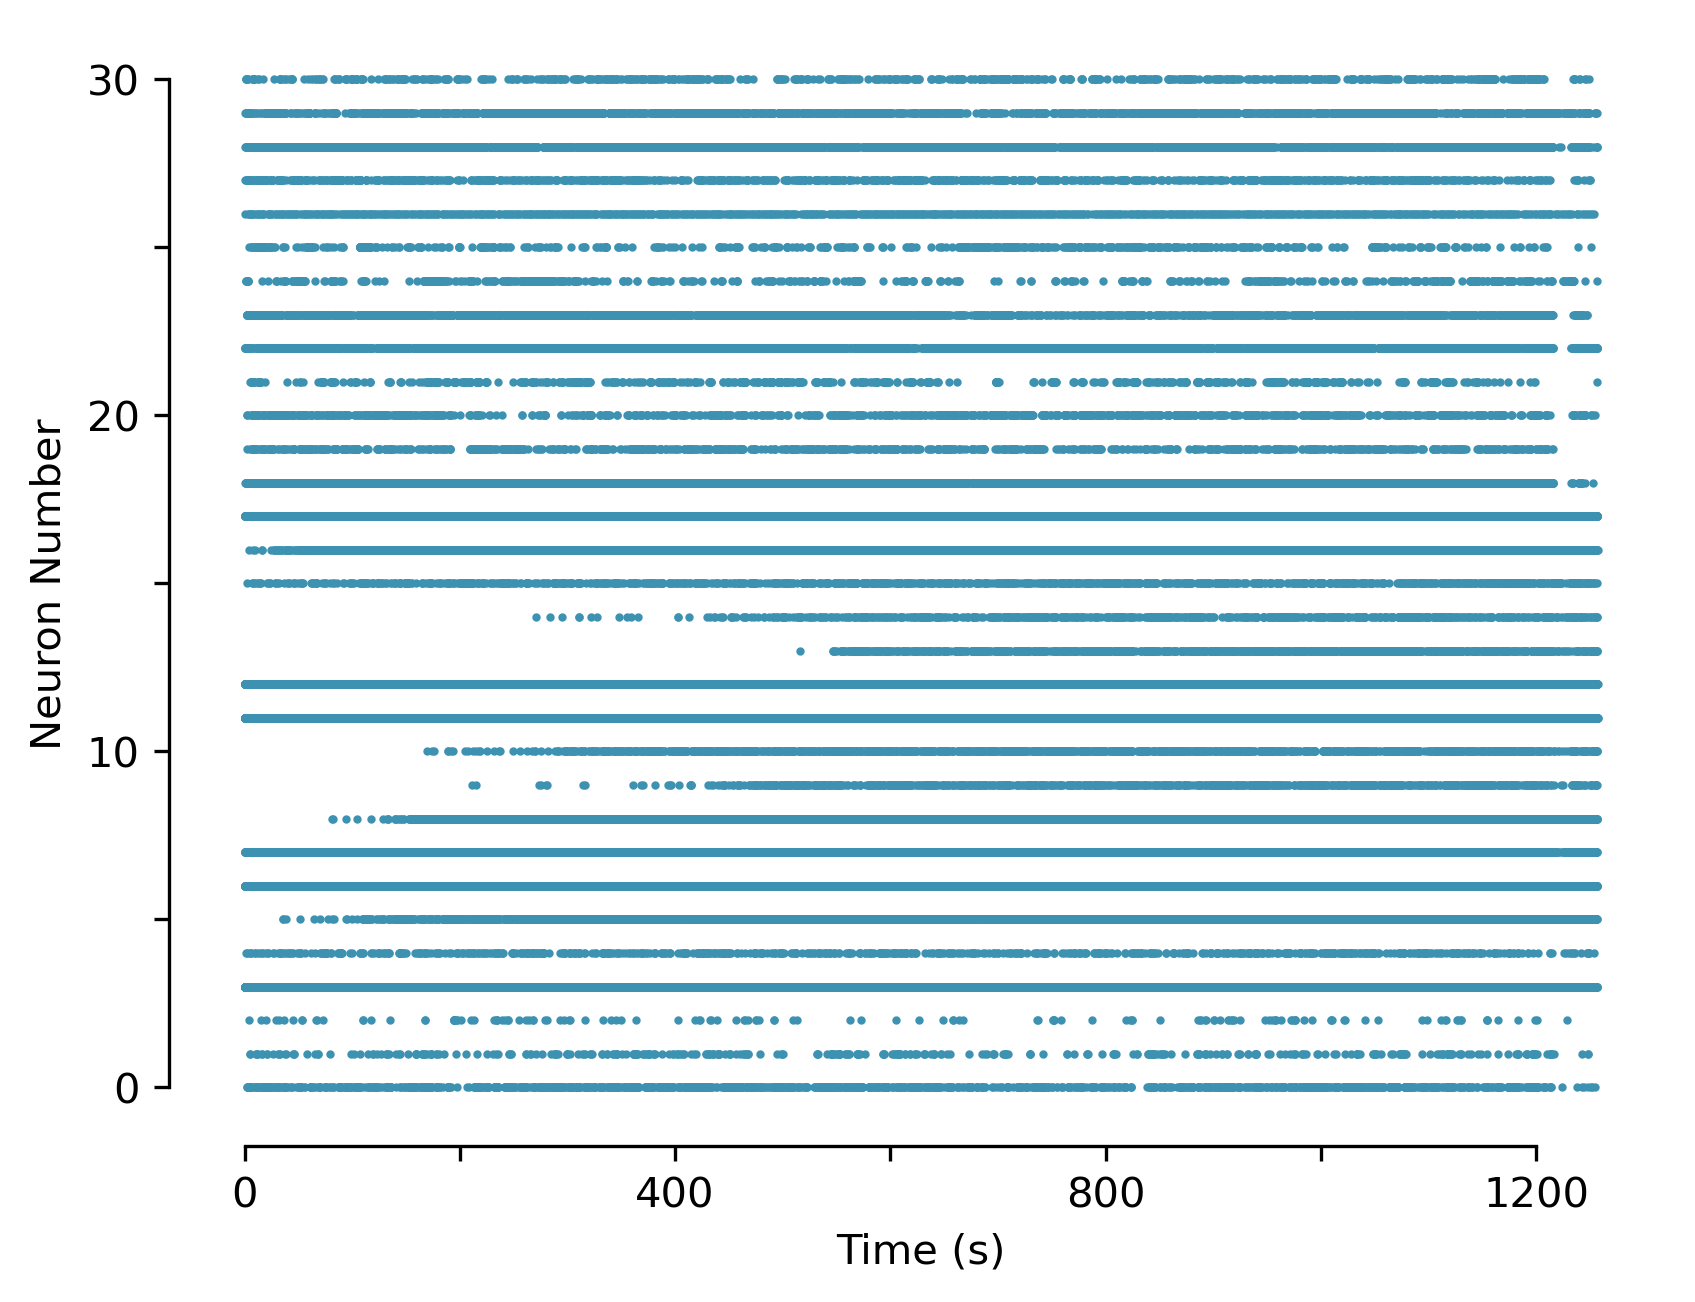

In [6]:
# plot general raster of all units in the session

for i in range(len(spike_times_all)-1):
    test = spike_ms[i]
    x = np.size(test)  # length
    y = i  # fill value
    my_list = [y] * x
    plt.scatter (test,my_list, s=1, color = '#3C92B0')
    plt.yticks ([0,5,10,15,20,25,30], ['0', '', '10', '', '20', '', '30'])
    plt.xticks ([0,200000,400000,600000,800000,1000000,1200000], 
               ['0', '', '400', '', '800', '', '1200'])
    plt.ylabel ("Neuron Number")
    plt.xlabel ("Time (s)")
    sns.despine(offset=2, trim=True) 
    plt.savefig("all_neurons_sub2session2.png")

In [7]:
probe_times = nwbfile.intervals['trials'].timestamps_Probe[:]
probe_times_ms = [x * 1000 for x in probe_times] # convert probe times to ms

<center>
    <font size=4><b><u>Lining Up</u></b><br>Zooming into the big picture, can the neural signals be decoded right when a choice needs to be made? To do so, the neural signals can be line up to when a specific picture was presented. This picture is the 'probe' picture - indicating to the person that they need to choose if they've seen this picture or not before. Here, the graph shows the neural signals of one neuron aligned to the time of the probe picture presentation. Each row represents one turn or 'trial' of this task and each dot, again, represents when the neuron has chattered. While there isn't anything too pronounced here, there is some extra chattering around the 1-2 seconds time period. 

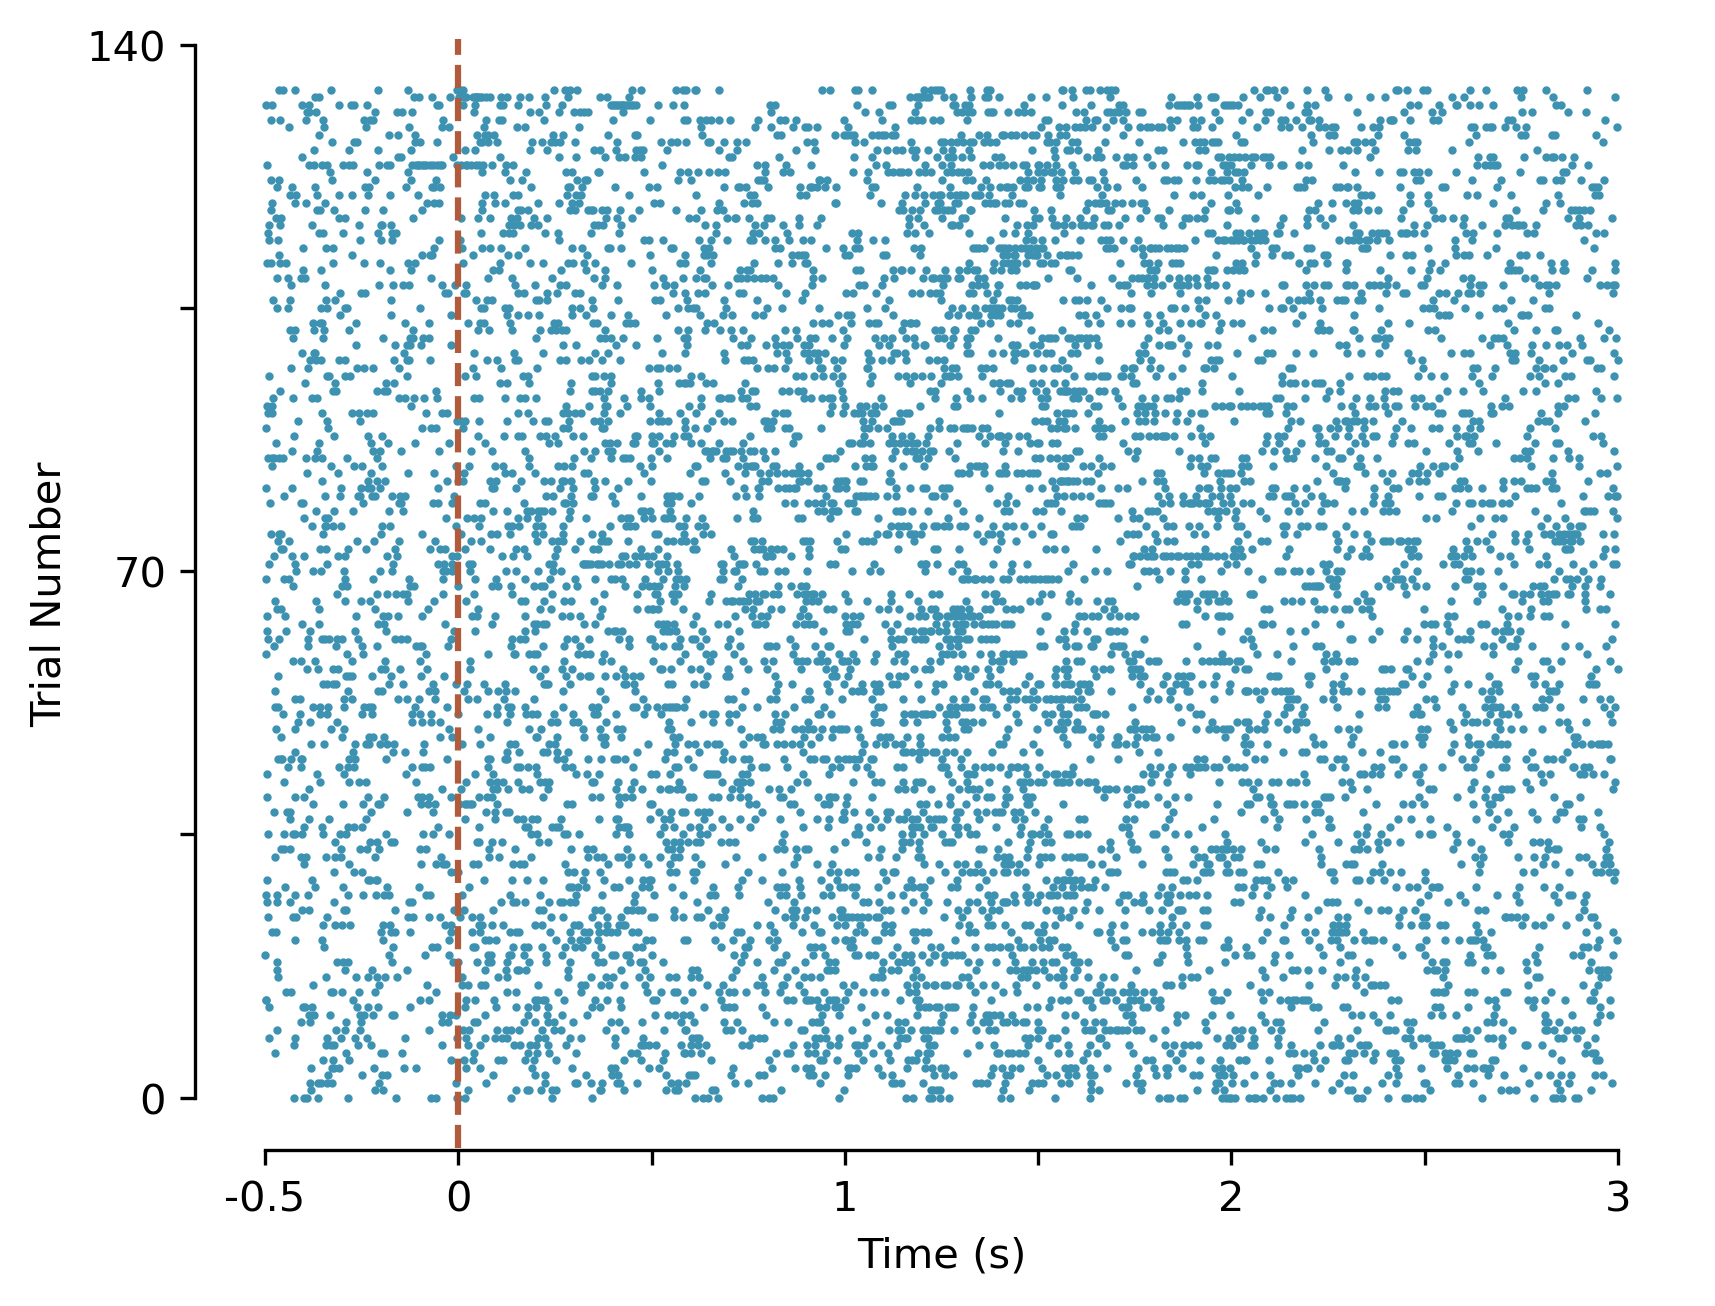

In [8]:
for i in range (len(probe_times_ms)): #go through each stim A presentations
    
    #determine the trial time range
    temp = probe_times_ms[i] #work with each time of Stim A in loop one-by-one
    pre = temp - 500 #find the absolute trial start time (in ms, 500 ms prior)
    post = temp + 3000 #find the absolute trial end time (in ms, 3000 ms after)
    
    #now that we have the range, find spikes that happened on this unit within the trial 
    #spike_trial is temporary variable within each loop
    spike_trial = spike_ms[3][(spike_ms[3] > pre) & (spike_ms[3] < post)] 
    spike_trial = [x - probe_times_ms[i] for x in spike_trial] #align so stim is at 0 ms
    
    #plot the spikes as as raster by trial
    plt.scatter (x=spike_trial, y=np.full(len(spike_trial),i), color = '#3C92B0', s=1)
    
    del (spike_trial)
    
plt.axvline(x=0, color='#B05B3C', linestyle='--', linewidth=1.5)
plt.yticks ([0,35,70,105,140], ['0', '', '70', '', '140'])
plt.xticks ([-500,0,500,1000,1500,2000,2500,3000], 
            ['-0.5','0', '', '1', '', '2', '', '3'])
plt.ylabel ("Trial Number")
plt.xlabel ("Time (s)")
sns.despine(offset=0.5, trim=True) 
plt.savefig("raster_id03_sub2session2.png")

In [9]:

matrix = np.zeros((len (probe_times_ms), 3501)) #preallocate in ms, 500 pre stim, 200 post stim, 10 trials

for i in range (len (probe_times_ms)): #all trials
    temp = probe_times_ms[i]
    pre = temp - 500
    post = temp + 3000
    spike_trial = spike_ms[3][(spike_ms[3] > pre) & (spike_ms[3] < post)] #0 here represents first neuron
    spike_trial = [x - probe_times_ms[i] for x in spike_trial]

    rounded_spikes = np.round(spike_trial).astype(int)
    rounded_spikes = rounded_spikes + 500 #align time so that start of trial (500 ms pre) is 0

    for j in range(len(rounded_spikes)): 
        matrix[i][rounded_spikes[j]]=1

In [10]:
smoothed_data = gaussian_filter(matrix, sigma=(0,30))
average = np.mean (smoothed_data, axis=0)
std = np.std (smoothed_data, axis=0)
sterr = std/np.sqrt(len (probe_times_ms))
t = np.arange(0,3501,1)

<center>
    <font size=4><b><u>Average It Out</u></b><br>To look at the extra chattering more closely, the aligned neural signals can be averaged to look at the average response across all the trials. Once average, the bump becomes more obvious at 1.5-2 seconds. 

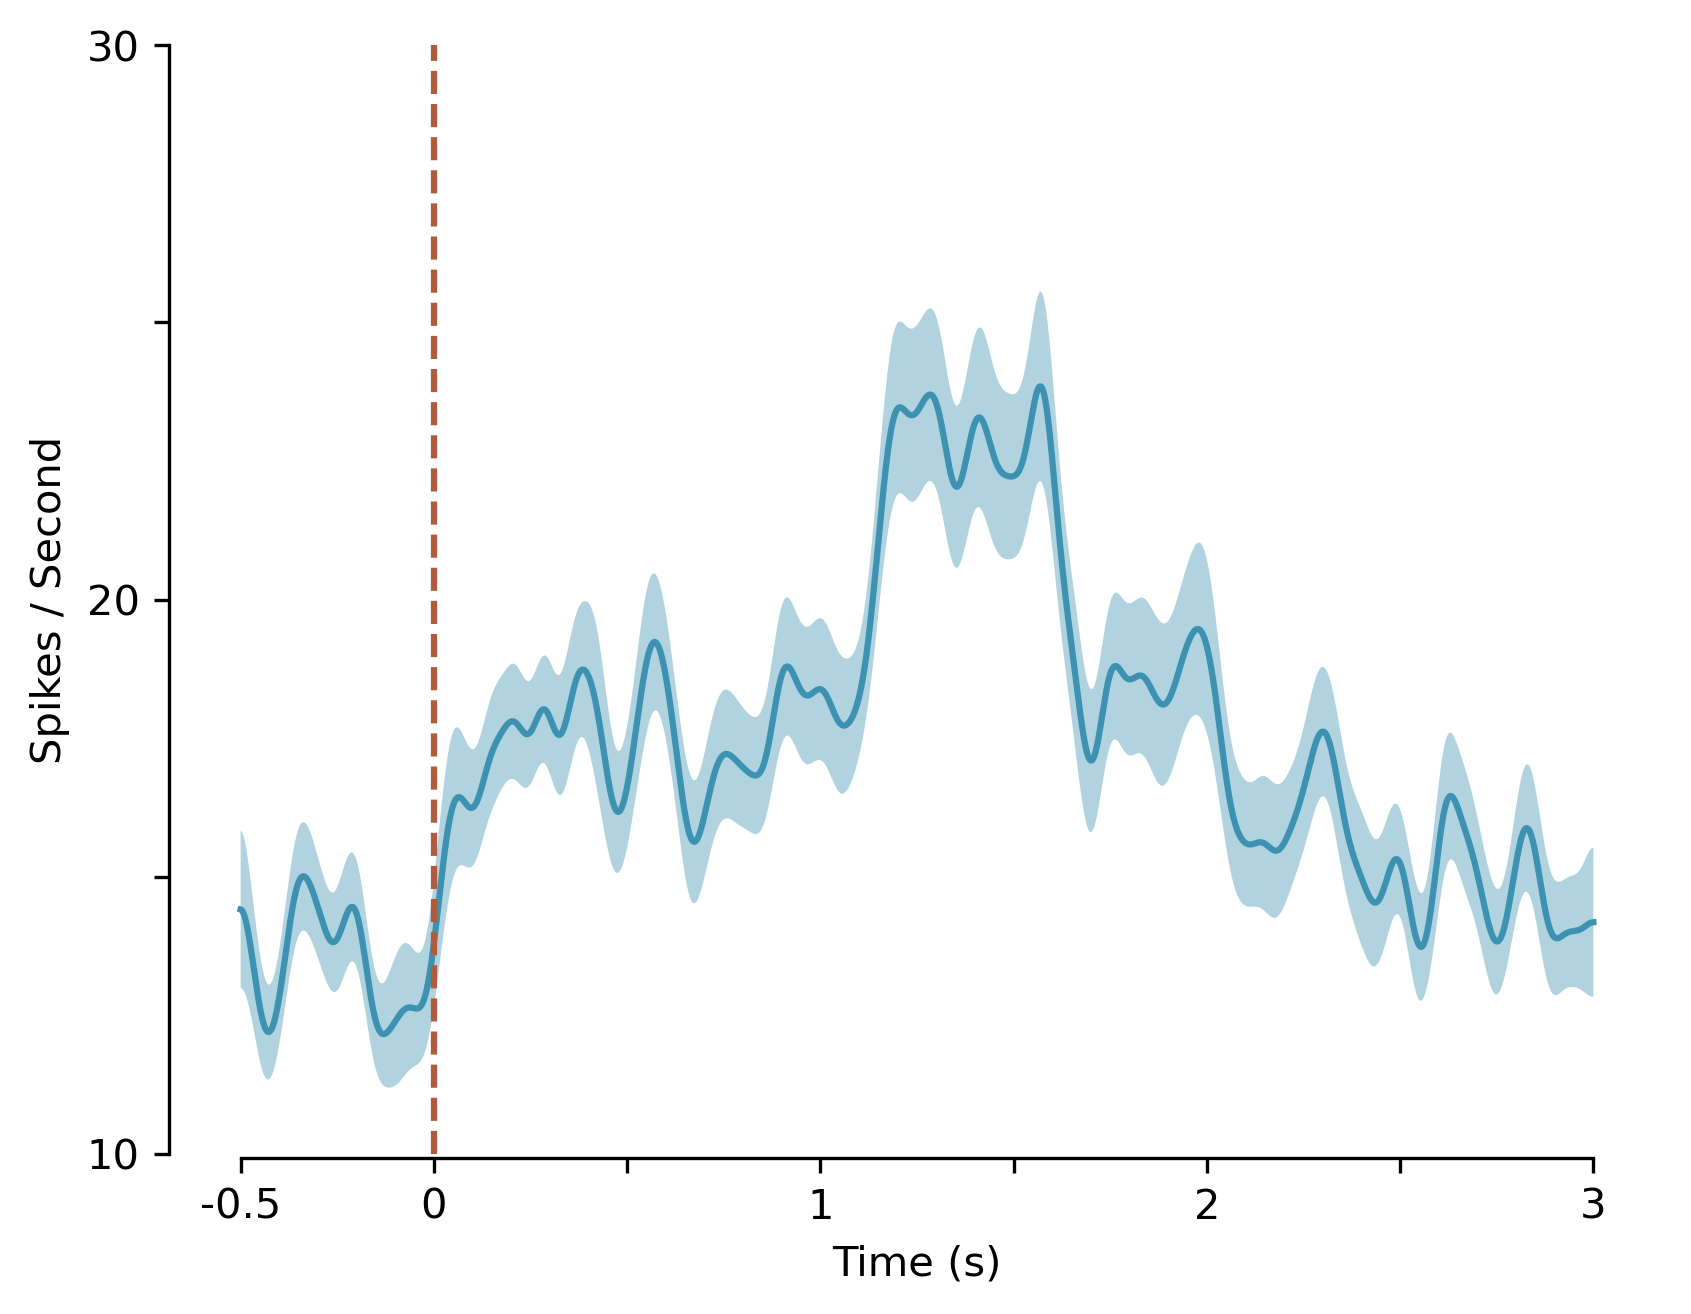

In [11]:
plt.plot(t, average,'-', color='#3C92B0')
plt.fill_between(t, average - sterr, average + sterr, alpha=0.4, color='#3C92B0', edgecolor='none')

plt.axvline(x=500, color='#B05B3C', linestyle='--', linewidth=1.5)
plt.yticks ([0.01,0.015,0.02,0.025, 0.03], ['10','', '20','', '30'])
plt.xticks ([0,500,1000,1500,2000,2500,3000,3500], 
            ['-0.5','0', '', '1', '', '2', '', '3'])
plt.ylabel ("Spikes / Second")
plt.xlabel ("Time (s)")
sns.despine(offset=1, trim=True) 
plt.savefig("averagepsth_id03_sub2session2.png")

In [12]:
response = nwbfile.intervals['trials'].response_accuracy[:] #extract response data

In [13]:
unit = int(3)
## here, matrix (all trials) of unit #4 ('3')

matrix = np.zeros((len (probe_times_ms), 3501)) #preallocate in ms, 500 pre stim, 200 post stim, 10 trials

for i in range (len (probe_times_ms)): #all trials
    temp = probe_times_ms[i]
    pre = temp - 500
    post = temp + 3000
    spike_trial = spike_ms[unit][(spike_ms[unit] > pre) & (spike_ms[unit] < post)] #0 here represents first neuron
    spike_trial = [x - probe_times_ms[i] for x in spike_trial]

    rounded_spikes = np.round(spike_trial).astype(int)
    rounded_spikes = rounded_spikes + 500 #align time so that start of trial (500 ms pre) is 0

    for j in range(len(rounded_spikes)): 
        matrix[i][rounded_spikes[j]]=1

        
###        
matrix_right = matrix[np.where(response == 1)] #index of trials the choice was correct
matrix_wrong = matrix[np.where(response == 0)] #index of trials the choice was incorrect


<center>
    <font size=4><b><u>Looking Deeper</u></b><br>If the neural activity during this time period does represent the choice ('encoding'), do the signals look different between the two choices? (change so it's not about choice but framed as memory). In the graph below, the average neural responses are graphed but separated as the wrong choice (orange) and the correct choice (blue). Generally, the two averages look very similar. 

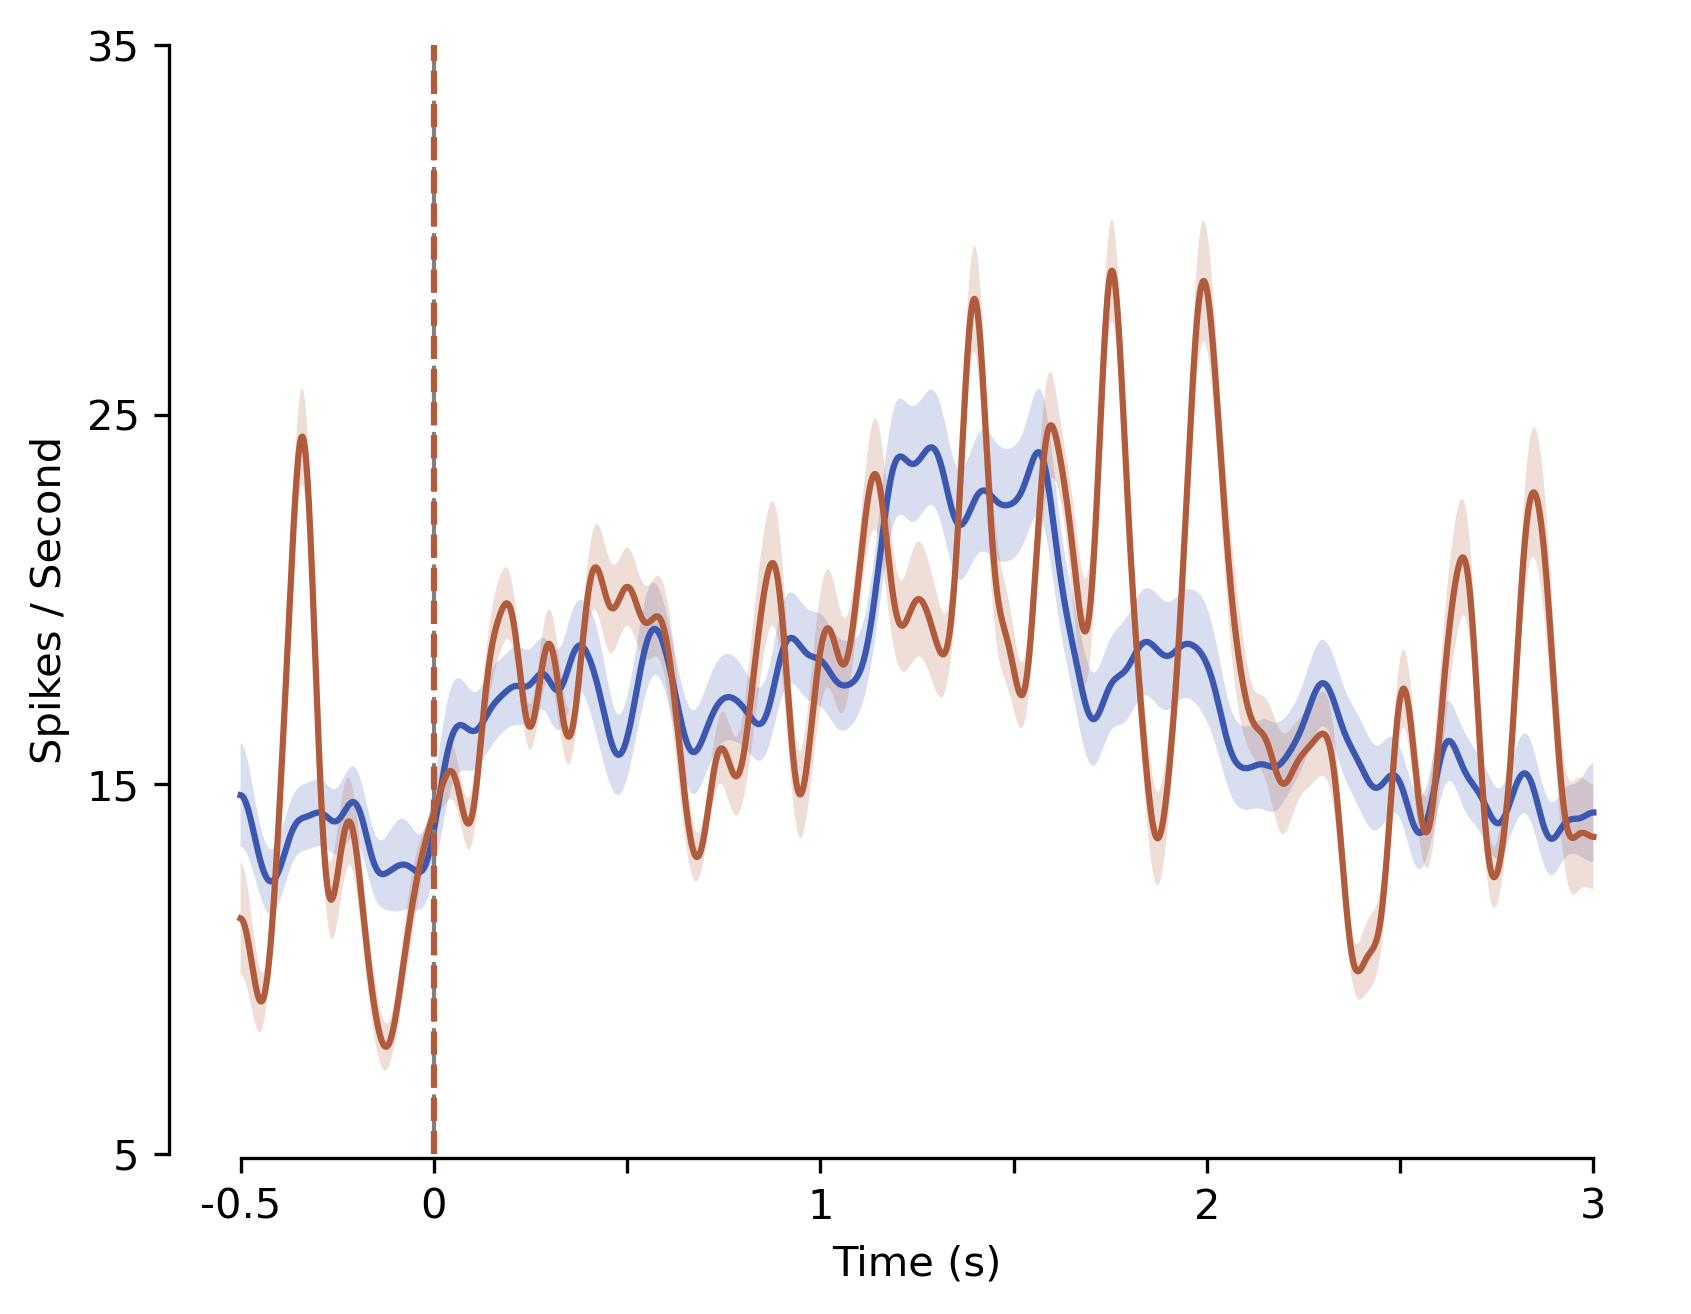

In [14]:
smoothed_data_R = gaussian_filter(matrix_right, sigma=(0,30))
average = np.mean (smoothed_data_R, axis=0)
std = np.std (smoothed_data_R, axis=0)
sterr = std/np.sqrt(len(probe_times_ms))
t = np.arange(0,3501,1)

plt.plot(t, average,'-', color='#3C57B0')
plt.fill_between(t, average - sterr, average + sterr, alpha=0.2, color='#3C57B0', edgecolor='none')


smoothed_data_W = gaussian_filter(matrix_wrong, sigma=(0,30))
average = np.mean (smoothed_data_W, axis=0)
std = np.std (smoothed_data_W, axis=0)
sterr = std/np.sqrt(len(probe_times_ms))
t = np.arange(0,3501,1)

plt.plot(t, average,'-', color='#B05B3C')
plt.fill_between(t, average - sterr, average + sterr, alpha=0.2, color='#B05B3C', edgecolor='none')
plt.axvline(x=500, color='grey', linestyle='--', linewidth=1)

plt.axvline(x=500, color='#B05B3C', linestyle='--', linewidth=1.5)
plt.yticks ([0.005,0.015,0.025,0.035], ['5','15', '25','35'])
plt.xticks ([0,500,1000,1500,2000,2500,3000,3500], 
            ['-0.5','0', '', '1', '', '2', '', '3'])
plt.ylabel ("Spikes / Second")
plt.xlabel ("Time (s)")
sns.despine(offset=1, trim=True) 
plt.savefig("averagepsthsplit_id03_sub2session2.png")


<center>
    <font size=4><b><u>New School</u></b><br>Historically, neuroscientists would have stopped here and concluded that neurons like this are not 'encoding' (storing the information) the person's choice. However, recent developments in machine learning algorithms - complex calculations that rely on iterative computing power - allow for calculations beyond what was traditionally used. Could machine learning algorithms detect something that traditional methods cannot? 

In [15]:
matrix_full =np.zeros((1,3501))

for h in range (15): #this number here is the unit number 
    matrix = np.zeros((len (probe_times_ms), 3501)) #preallocate in ms, 500 pre stim, 200 post stim, 10 trials

    for i in range (len (probe_times_ms)): #first 10 trials 
        temp = probe_times_ms[i]
        pre = temp - 500
        post = temp + 3000
        spike_trial = spike_ms[h][(spike_ms[h] > pre) & (spike_ms[h] < post)] #0 here represents first neuron
        spike_trial = [x - probe_times_ms[i] for x in spike_trial]

        rounded_spikes = np.round(spike_trial).astype(int)
        rounded_spikes = rounded_spikes + 500 #align time so that start of trial (500 ms pre) is 0

        for j in range(len(rounded_spikes)): 
            matrix[i][rounded_spikes[j]]=1
            
    matrix_full = np.append (matrix, matrix_full, axis=0)

matrix_full = matrix_full[1:]

In [16]:
response_full = np.tile(response, 15)

In [17]:
#del matrix_full

In [18]:
print(np.shape(response_full))
print(np.shape(matrix_full))

(2025,)
(2025, 3501)


In [110]:
clf = RandomForestClassifier(n_estimators = 150, 
                             max_depth = 1, class_weight='balanced', oob_score=True)

In [111]:
clf.fit(matrix, response) #train the classifier 

RandomForestClassifier(class_weight='balanced', max_depth=1, n_estimators=150,
                       oob_score=True)

In [112]:
predictions = clf.predict(matrix_full) #predict with classifier

In [113]:
diff_model_response = np.count_nonzero (response_full != predictions)
inaccuracy = round((diff_model_response/len(matrix_full)*100),2)
print(inaccuracy)
accuracy = 100 - inaccuracy
print(accuracy)
print(f"OOB Score: {clf.oob_score_}")

9.04
90.96000000000001
OOB Score: 0.8962962962962963


In [125]:
n_ests = [25,50,100,150,200,250,300]
OOBs_ests = [0.607,0.674,0.911,0.911,0.903,0.903,0.911]

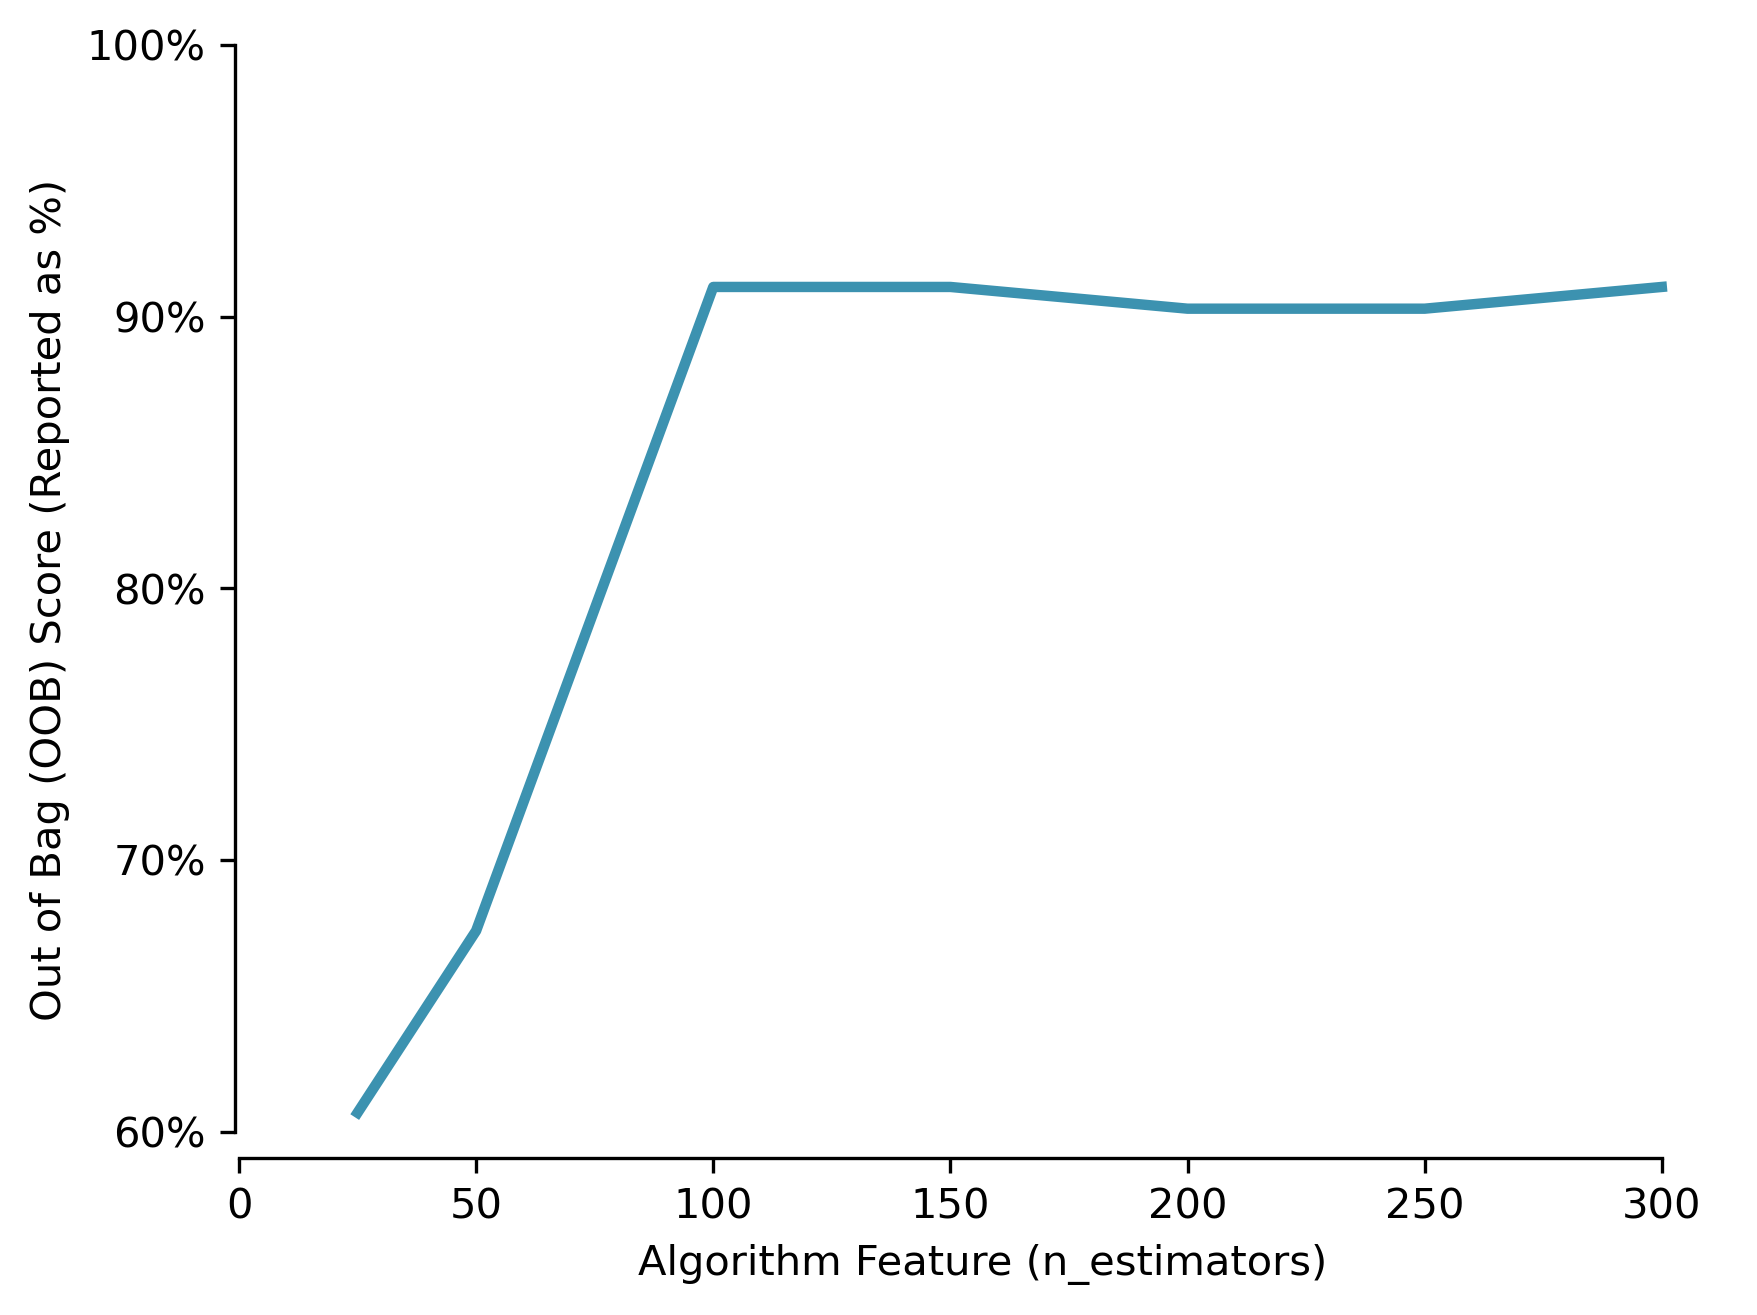

In [155]:
plt.plot(n_ests,OOBs_ests, color='#3C92B0', linewidth=2.5)


plt.yticks ([0.6,0.7,0.8,0.9,1.0], ['60%','70%', '80%','90%','100%'])
plt.xticks ([0,50,100,150,200,250,300], 
            ['0','50','100', '150', '200', '250', '300'])
plt.ylabel ("Out of Bag (OOB) Score (Reported as %)")
plt.xlabel ("Algorithm Feature (n_estimators)")
sns.despine(offset=1, trim=True) 
plt.savefig("rfc_nest_sub2session2.png")

In [148]:
depth = [1,3,5,7,9,11]
OOBs_depth = [0.896,0.896,0.903,0.837,0.903,0.911]

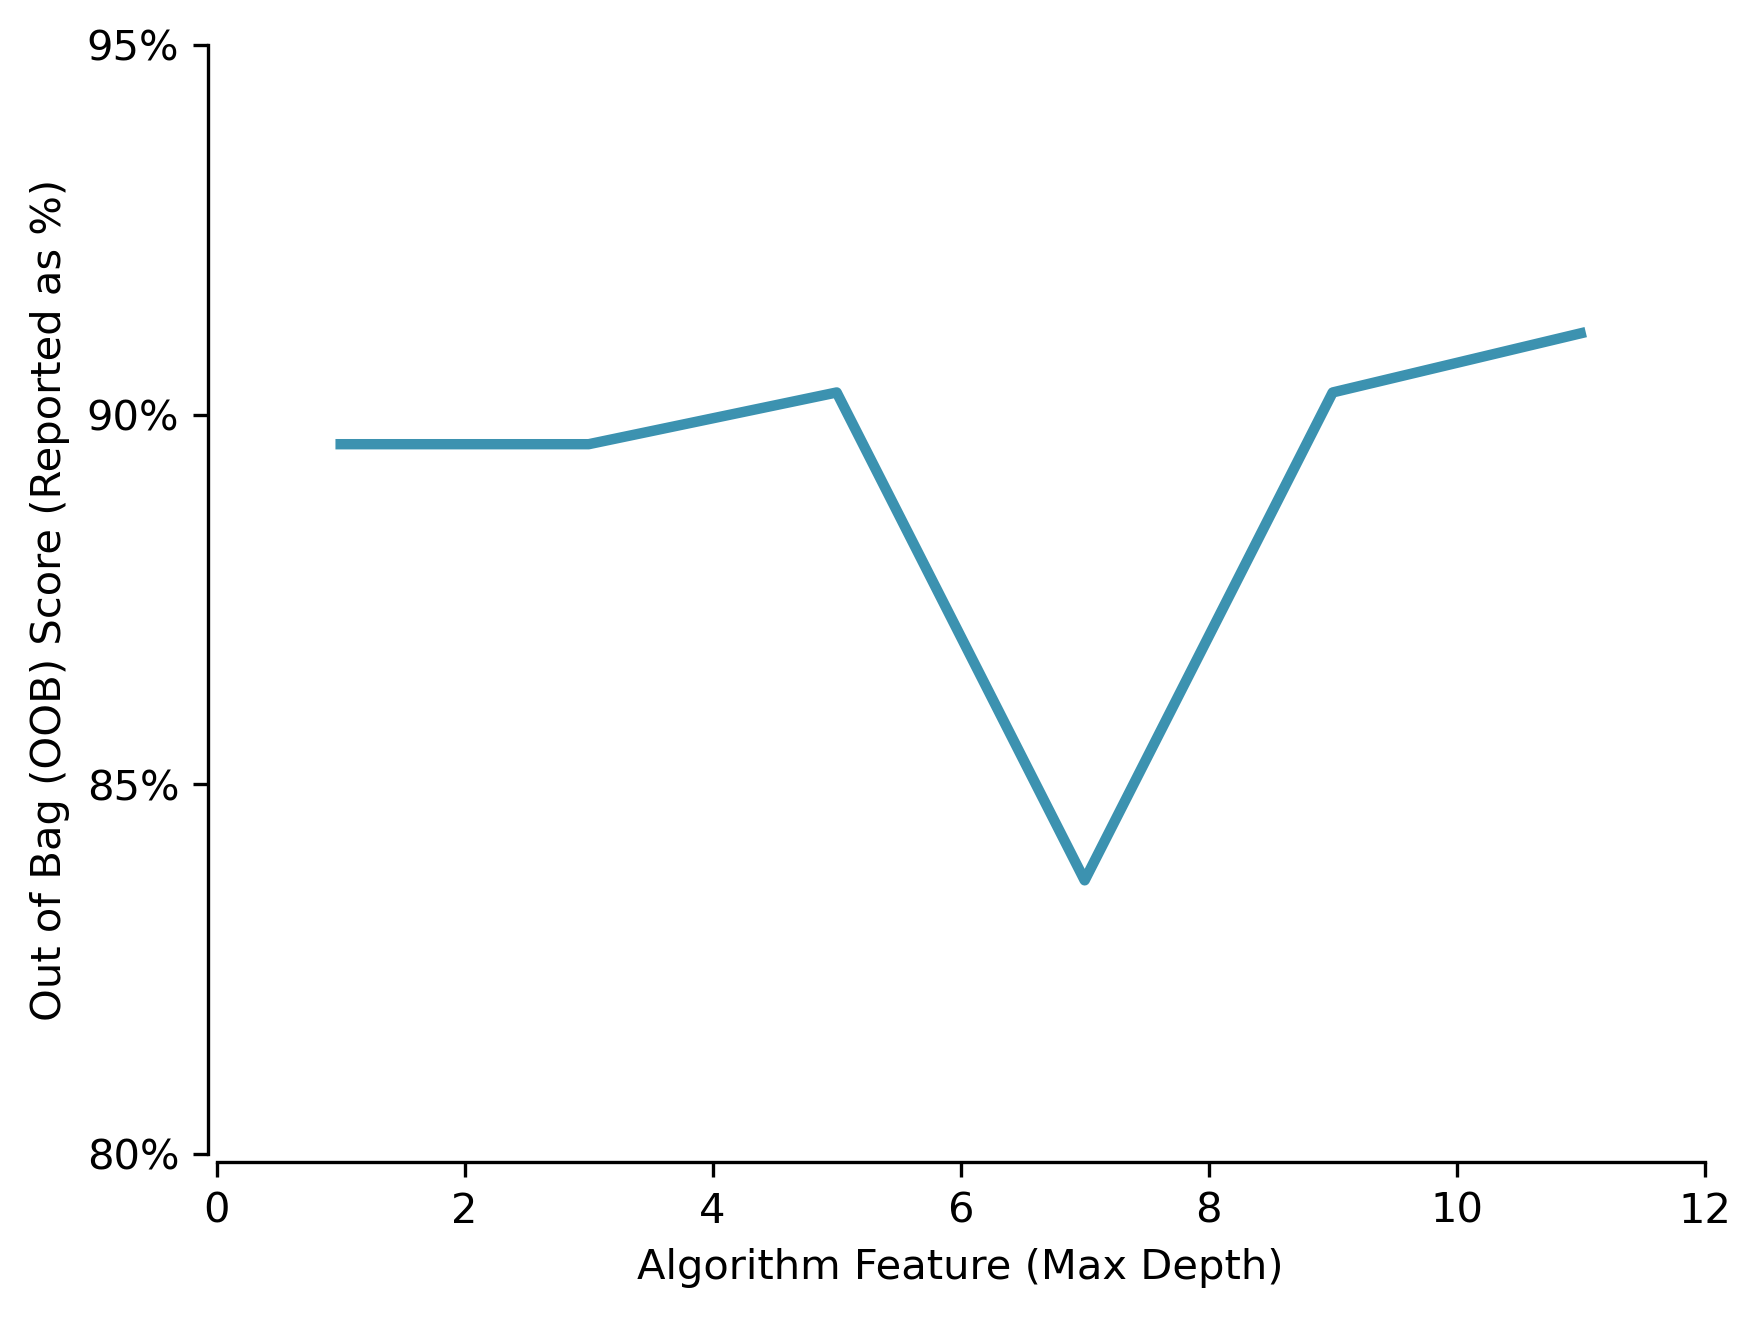

In [154]:
plt.plot(depth,OOBs_depth, color='#3C92B0', linewidth=2.5)


plt.yticks ([0.8,0.85,0.9,0.95], ['80%','85%','90%','95%'])
plt.xticks ([0,2,4,6,8,10,12], 
            ['0','2','4', '6', '8', '10', '12'])
plt.ylabel ("Out of Bag (OOB) Score (Reported as %)")
plt.xlabel ("Algorithm Feature (Max Depth)")
sns.despine(offset=2, trim=True) 
plt.savefig("rfc_mdepth_sub2session2.png")

In [138]:
clf = RandomForestClassifier(n_estimators = 150, 
                             max_depth = 7, class_weight='balanced', oob_score=True)

In [139]:
clf.fit(matrix, response) #train the classifier 

RandomForestClassifier(class_weight='balanced', max_depth=7, n_estimators=150,
                       oob_score=True)

In [140]:
predictions = clf.predict(matrix_full) #predict with classifier

In [141]:
diff_model_response = np.count_nonzero (response_full != predictions)
inaccuracy = round((diff_model_response/len(matrix_full)*100),2)
print(inaccuracy)
accuracy = 100 - inaccuracy
print(accuracy)
print(f"OOB Score: {clf.oob_score_}")

10.67
89.33
OOB Score: 0.9037037037037037


In [ ]:
#probs = clf.predict_proba(matrix_right)[:, 1]
#custom_predictions = (probs > 0.7).astype(int)